# Modelo de Grau Nublado (Fuzzy)

In [1]:
caminho_do_arquivo = '/media/juan/SSD_D/ufc/2026.2/instrumentação/Projeto_grupo_4/Projeto/eplusout.csv'

In [3]:
import os
import numpy as np
import matplotlib.pyplot as plt

ModuleNotFoundError: No module named 'numpy'

In [ ]:
import pandas as pd
from scipy.stats import qmc

In [ ]:
!pip install -U scikit-fuzzy matplotlib
import skfuzzy as fuzz
from skfuzzy import control as ctrl

In [ ]:
%pip install networkx

Note: you may need to restart the kernel to use updated packages.


In [ ]:
pip install scipy

Note: you may need to restart the kernel to use updated packages.


In [ ]:
pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [ ]:
pip install scikit-fuzzy

Note: you may need to restart the kernel to use updated packages.


In [ ]:
pip install pandas

Note: you may need to restart the kernel to use updated packages.


---

### Definição do LHS Hipercubo Latino

Aplicação usando um parametro genérico de exemplo

In [ ]:
limites_parametros = {
    'temp_setpoint': [18.0, 26.0],       # Ex: Temperatura (°C)
    'potencia_equip': [1000.0, 5000.0],  # Ex: Carga térmica (W)
    'taxa_infiltracao': [0.1, 1.5],      # Ex: Trocas de ar/h
    'n_ocupantes': [1, 18]               # Ex: Número de pessoas
}

max temp = 35.13
max uhmidade 24 temp

# Definição do Fuzzy Trápezio

descrição de informações uteis:
Amostragem por hipercubo latino é um método de simulação, semelhante ao método de Monte Carlo, que, na maioria dos casos, converge para melhores resultados do que Monte Carlo.

método de uma classe de métodos estatísticos que se baseiam em amostragens aleatórias massivas para obter resultados numéricos. Em suma, utilizam a aleatoriedade de dados para gerar um resultado para problemas que a priori são determinísticos. São utilizados mais comumente em problemas de física e de matemática onde são muito difíceis ou impossível de serem resolvidos com outros métodos.


## Aplicação de Amostragem de Hipercubo latino com os dados obtidos

In [ ]:
# 1. Carregar o arquivo original CSV do EnergyPlus
df_original = pd.read_csv('epluszsz.csv')

In [ ]:
colunas_alvo = [
    'THERMAL ZONE 1:QUIXERAMOBIM SUMMER DESIGN DAY:Cooling Zone Temperature [C]',
    'THERMAL ZONE 1:QUIXERAMOBIM SUMMER DESIGN DAY:Cooling Zone Relative Humidity [%]'
]

In [ ]:
df_base = df_original[colunas_alvo].copy()

In [ ]:
df_base.columns = ['Temperatura_Base_C', 'Umidade_Base_%']

In [ ]:
temp_min, temp_max = df_base['Temperatura_Base_C'].min(), df_base['Temperatura_Base_C'].max()
umid_min, umid_max = df_base['Umidade_Base_%'].min(), df_base['Umidade_Base_%'].max()

In [ ]:
print(f"Limites Físicos da Sala Base:")
print(f"Temperatura (°C): de {temp_min:.2f} a {temp_max:.2f}")
print(f"Umidade Relativa (%): de {umid_min:.2f} a {umid_max:.2f}\n")

Limites Físicos da Sala Base:
Temperatura (°C): de 20.73 a 22.31
Umidade Relativa (%): de 60.07 a 90.52



In [ ]:
from scipy.stats import qmc

N_SIMULACOES = 200
N_VARIAVEIS = 2 # Estamos amostrando Temperatura e Umidade

In [ ]:
# Inicializa o gerador de Hipercubo Latino no espaço unitário [0,1]
sampler = qmc.LatinHypercube(d=N_VARIAVEIS, seed=42)
amostras_unitarias = sampler.random(n=N_SIMULACOES)

# com os limites da simulação base exportada pelo grupo 2
limites_inferiores = [temp_min, umid_min]
limites_superiores = [temp_max, umid_max]

amostras_projetadas = qmc.scale(amostras_unitarias, limites_inferiores, limites_superiores)

# Converter o resultado para o banco de dados final (DataFrame)
df_lhs_banco = pd.DataFrame(
    amostras_projetadas, 
    columns=['LHS_Temperatura_C', 'LHS_Umidade_%']
)

# Salvar como um novo CSV limpo
df_lhs_banco.to_csv('banco_dados_lhs_200.csv', index=False)

print("Primeiras amostras LHS geradas:")
print(df_lhs_banco)

Primeiras amostras LHS geradas:
     LHS_Temperatura_C  LHS_Umidade_%
0            22.142539      86.649246
1            21.548556      71.081899
2            21.064131      69.212716
3            22.190106      83.399452
4            21.032219      69.444911
..                 ...            ...
195          21.249696      61.883152
196          22.302226      77.934201
197          21.721379      64.877255
198          20.860575      69.772982
199          21.203643      78.580255

[200 rows x 2 columns]


---

### Definições para o Fuzzy e DeFuzzy

In [ ]:
def pertinencia_triangular(x, params):
    # params: [a, b, c]
    # a, c: limites inferiores (pertinência = 0)
    # b: pico (pertinência = 1)
    a, b, c = params
    x = np.asarray(x)
    subida = np.zeros_like(x, dtype=float)
    descida = np.zeros_like(x, dtype=float)
    
    idx_sub = (x > a) & (x <= b)
    idx_desc = (x > b) & (x < c)
    
    if b > a: subida[idx_sub] = (x[idx_sub] - a) / (b - a)
    else: subida[idx_sub] = 1.0
        
    if c > b: descida[idx_desc] = (c - x[idx_desc]) / (c - b)
    else: descida[idx_desc] = 1.0
        
    return np.maximum(0.0, np.minimum(subida + descida, 1.0))

In [ ]:
def pertinencia_trapezoidal(x, params):
    a, b, c, d = params
    x = np.asarray(x)
    resultado = np.zeros_like(x, dtype=float)
    idx_sub = (x >= a) & (x < b)
    idx_plato = (x >= b) & (x <= c)
    idx_desc = (x > c) & (x <= d)
    if b > a: resultado[idx_sub] = (x[idx_sub] - a) / (b - a)
    else: resultado[idx_sub] = 1.0
    resultado[idx_plato] = 1.0
    if d > c: resultado[idx_desc] = (d - x[idx_desc]) / (d - c)
    else: resultado[idx_desc] = 1.0
    return np.maximum(0.0, np.minimum(resultado, 1.0))

In [ ]:
y_universo = np.linspace(0, 100, 1000)

---

In [ ]:
saida_media = pertinencia_triangular(y_universo, [20, 50, 80])
saida_alta  = pertinencia_triangular(y_universo, [60, 85, 100])

In [ ]:
# 2. Valores lidos pelo sensor (crisp)
temp_sensor = 32.0 
press_sensor = 11.5

In [ ]:
# 3. Fuzzificando os sinais do sensor
grau_temp_alta = pertinencia_triangular(temp_sensor, [25, 35, 45])
grau_press_normal = pertinencia_triangular(press_sensor, [6, 10, 13])


In [ ]:
mu_press_normal = pertinencia_triangular(press_sensor, [6, 10, 13])
mu_press_alta = pertinencia_trapezoidal(press_sensor, [9, 11, 15, 15])
mu_temp_alta = pertinencia_triangular(temp_sensor, [25, 35, 45])

---

## Aplicação do dado Crisp para uma variavel nebulosa Fuzzy

In [ ]:
# Eixo da Temperatura (°C)
temp_crisp = 22.142539
x_temp = np.linspace(15, 45, 500)

# Criando as curvas: Frio (x), Morno (y), Quente (z)
mu_frio = pertinencia_triangular(x_temp, [15, 15, 25])
mu_morno = pertinencia_triangular(x_temp, [20, 25, 32])
mu_quente = pertinencia_trapezoidal(x_temp, [28, 35, 45, 45])
# Valor numérico exato medido pelo sensor (Input Crisp)

grau_frio = float(pertinencia_triangular(temp_crisp, [15, 15, 25]))
grau_morno = float(pertinencia_triangular(temp_crisp, [20, 25, 32]))
grau_quente = float(pertinencia_trapezoidal(temp_crisp, [28, 35, 45, 45]))

# O array final que será levado para a base de regras
array_fuzzificado = [grau_frio, grau_morno, grau_quente]



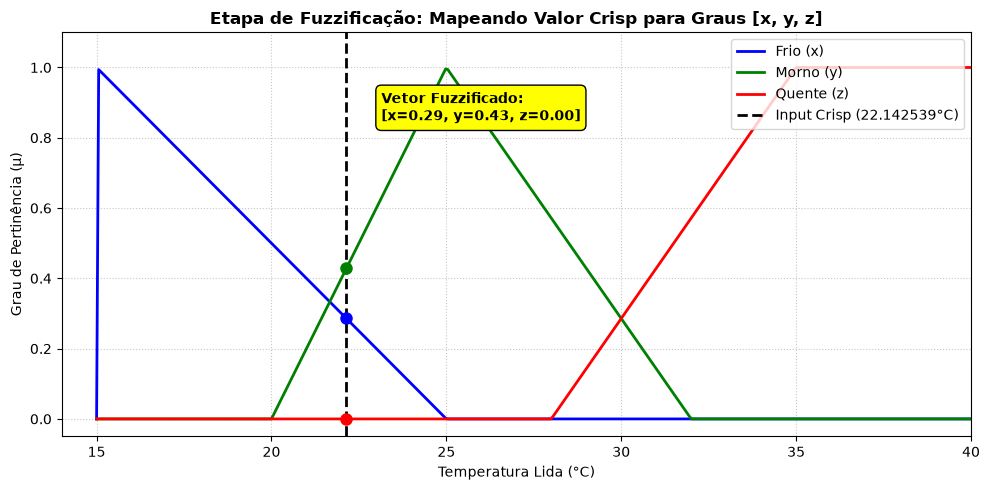

Array Fuzzificado [x, y, z] resultante: [0.28574610000000006, 0.4285077999999999, 0.0]


In [ ]:
plt.figure(figsize=(10, 5), dpi=100)

# A. Desenhando as variáveis linguísticas
plt.plot(x_temp, mu_frio, 'b-', linewidth=2, label='Frio (x)')
plt.plot(x_temp, mu_morno, 'g-', linewidth=2, label='Morno (y)')
plt.plot(x_temp, mu_quente, 'r-', linewidth=2, label='Quente (z)')

# B. Traçando a linha vertical do valor Crisp
plt.axvline(temp_crisp, color='k', linestyle='--', linewidth=2, label=f'Input Crisp ({temp_crisp}°C)')

# C. Marcando as interseções (Graus de Pertinência de cada conjunto)
plt.plot(temp_crisp, grau_frio, 'bo', markersize=8)
plt.plot(temp_crisp, grau_morno, 'go', markersize=8)
plt.plot(temp_crisp, grau_quente, 'ro', markersize=8)

# D. Adicionando a caixa de anotação com o Array
texto_anotacao = f'Vetor Fuzzificado:\n[x={grau_frio:.2f}, y={grau_morno:.2f}, z={grau_quente:.2f}]'
plt.annotate(texto_anotacao,
             xy=(temp_crisp, max(grau_frio, grau_morno, grau_quente)), 
             xytext=(temp_crisp + 1, 0.85),
             bbox=dict(boxstyle="round,pad=0.4", fc="yellow", ec="black", lw=1),
             fontsize=10, fontweight='bold')

plt.title('Etapa de Fuzzificação: Mapeando Valor Crisp para Graus [x, y, z]', fontsize=12, fontweight='bold')
plt.xlabel('Temperatura Lida (°C)')
plt.ylabel('Grau de Pertinência (\u03bc)')
plt.xlim(14, 40)
plt.ylim(-0.05, 1.1)
plt.legend(loc='upper right')
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()

# Exibe o Gráfico e Imprime o Vetor no Terminal
plt.show()
print(f"Array Fuzzificado [x, y, z] resultante: {array_fuzzificado}")

---

## Inferencia e Saída


O Centroide exato para atuar o ar-condicionado é: 39.35%


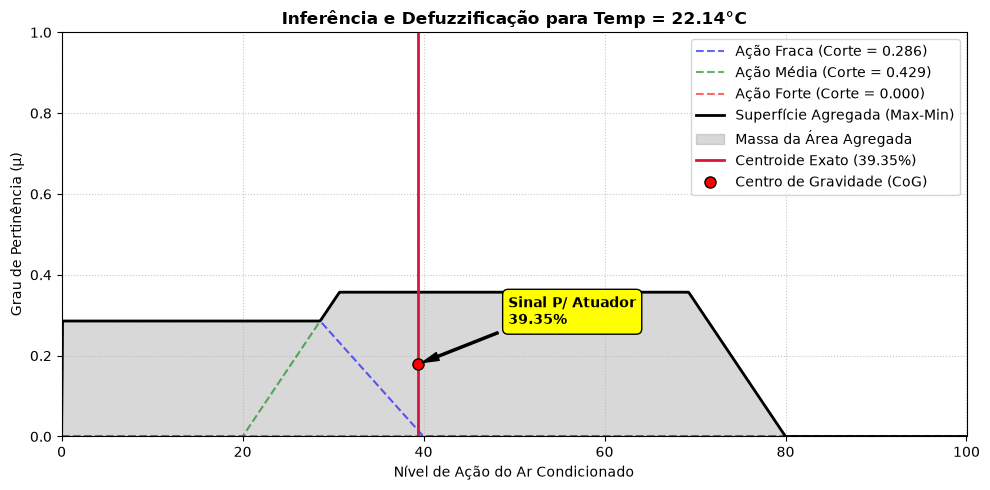

In [ ]:

# O array fuzzificado que você obteve para 22.14°C
grau_frio = array_fuzzificado[0]
grau_morno = array_fuzzificado[1]
grau_quente = array_fuzzificado[2]

grau_frio_float = float(pertinencia_triangular(temp_crisp, [15, 15, 25]))     # corresponde ao 'x'
grau_morno_float = float(pertinencia_triangular(temp_crisp, [20, 26, 32]))     # corresponde ao 'y'
grau_quente_float = float(pertinencia_trapezoidal(temp_crisp, [28, 35, 45, 45])) # corresponde ao 'z'

# Eixo X do gráfico (Universo de saída de 0 a 100% de uso do ar)
y_out = np.linspace(0, 100, 1000)

# Respostas do atuador mapeadas
saida_fraca = pertinencia_triangular(y_out, [0, 0, 40])
saida_media = pertinencia_triangular(y_out, [20, 50, 80])
saida_forte = pertinencia_trapezoidal(y_out, [60, 85, 100, 100])

# Interseção de Zadeh (Regra E/Mínimo) - Cortando o topo das curvas
ativacao_fraca = np.minimum(grau_frio_float, saida_fraca)
ativacao_media = np.minimum(grau_morno_float, saida_media)
ativacao_forte = np.minimum(grau_quente_float, saida_forte)

# União de Zadeh (Regra OU/Máximo) - Agregando todas as regras ativadas
superficie = np.maximum(ativacao_fraca, np.maximum(ativacao_media, ativacao_forte))

# =================================================================
# 3. CÁLCULO MATEMÁTICO DO CENTROIDE
# =================================================================
numerador = np.sum(y_out * superficie)
denominador = np.sum(superficie)
centroide = numerador / denominador

# Achando a posição do y para plotar o marcador certinho
idx_cent = (np.abs(y_out - centroide)).argmin()
mu_cent = superficie[idx_cent]

print(f"O Centroide exato para atuar o ar-condicionado é: {centroide:.2f}%")

# =================================================================
# 4. PLOTAGEM DO GRÁFICO (Matplotlib)
# =================================================================
plt.figure(figsize=(10, 5), dpi=100)

plt.plot(y_out, ativacao_fraca, 'b--', alpha=0.6, label=f'Ação Fraca (Corte = {grau_frio:.3f})')
plt.plot(y_out, ativacao_media, 'g--', alpha=0.6, label=f'Ação Média (Corte = {grau_morno:.3f})')
plt.plot(y_out, ativacao_forte, 'r--', alpha=0.6, label=f'Ação Forte (Corte = {grau_quente:.3f})')

plt.plot(y_out, superficie, 'k-', linewidth=2, label='Superfície Agregada (Max-Min)')
plt.fill_between(y_out, 0, superficie, color='gray', alpha=0.3, label='Massa da Área Agregada')

plt.axvline(centroide, color='crimson', linestyle='-', linewidth=2, label=f'Centroide Exato ({centroide:.2f}%)')
plt.plot(centroide, mu_cent/2, 'ro', markersize=8, markeredgecolor='black', label='Centro de Gravidade (CoG)')

plt.annotate(f'Sinal P/ Atuador\n{centroide:.2f}%', 
             xy=(centroide, mu_cent / 2.0), 
             xytext=(centroide + 10, mu_cent / 2.0 + 0.1),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=6),
             fontsize=10, fontweight='bold', bbox=dict(boxstyle="round,pad=0.4", fc="yellow", ec="black", lw=1))

plt.title('Inferência e Defuzzificação para Temp = 22.14°C', fontsize=12, fontweight='bold')
plt.xlabel('Nível de Ação do Ar Condicionado')
plt.ylabel('Grau de Pertinência (\u03bc)')
plt.xlim(0, 100)
plt.ylim(0, 1.0)
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend(loc='upper right')
plt.tight_layout()

plt.show()

---